# PhishGuard AI: original raw-URL research

This notebook examines the real dataset and verifies saved held-out outputs. Training is reproducible with `backend/train.py`; no source notebook is copied. Positive class = phishing. No URLs are visited.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, roc_auc_score
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
raw=pd.read_csv(ROOT/'data/raw-url/malicious_phish.csv')
d=pd.read_csv(ROOT/'data/raw-url/prepared.csv')
X=pd.read_csv(ROOT/'data/raw-url/features.csv')
m=json.loads((ROOT/'backend/models/metrics.json').read_text())
charts=ROOT/'reports/charts'; charts.mkdir(exist_ok=True)
print(raw.shape,raw.dtypes,raw.isna().sum(), 'duplicates:',raw.duplicated().sum(),sep='\n')
print(m['dataset']); print(m['split'])

(651191, 2)
url     str
type    str
dtype: object
url     0
type    0
dtype: int64
duplicates:
10066
{'raw_rows': 651191, 'raw_columns': ['url', 'type'], 'raw_classes': {'benign': 428103, 'defacement': 96457, 'phishing': 94111, 'malware': 32520}, 'missing': {'url': 0, 'type': 0}, 'raw_duplicates': 10066, 'invalid_binary_rows': 4175, 'conflicting_rows_removed': 7895, 'canonical_duplicates_removed': 258, 'retained': 509886, 'classes': {'benign': 420396, 'phishing': 89490}, 'feature_count': 19}
{'method': 'First fold of 5-fold StratifiedGroupKFold grouped by registrable domain (including private suffixes). Single held-out evaluation; no tuning.', 'train': 407908, 'test': 101978, 'domain_overlap': 0, 'train_classes': {'0': 336316, '1': 71592}, 'test_classes': {'0': 84080, '1': 17898}}


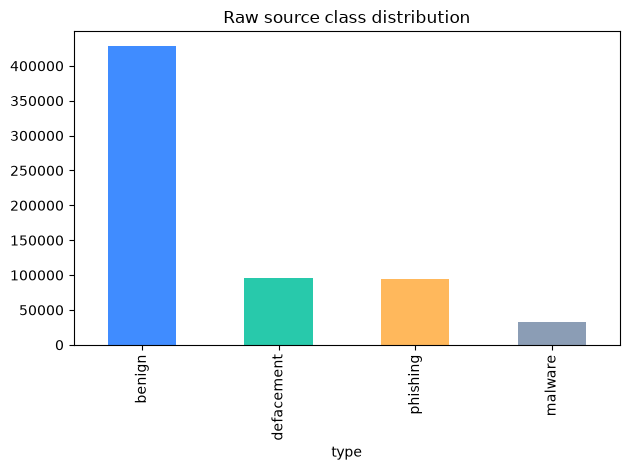

In [2]:
raw['type'].value_counts().plot.bar(color=['#408cff','#28c9ab','#ffb85c','#8b9db5'],title='Raw source class distribution'); plt.tight_layout(); plt.savefig(charts/'classes.png',dpi=180); plt.show()

## Preparation and leakage
Invalid inputs, conflicting canonical labels and duplicate canonical URLs are removed. Learned imputation/scaling fit only training data. Grouped domains reduce same-site overlap. The raw imbalance motivates training-only balanced class weights; all 19 numeric features are retained.

In [3]:
assert not set(d.loc[d.split=='train','domain']) & set(d.loc[d.split=='test','domain'])
assert not set(d.loc[d.split=='train','canonical']) & set(d.loc[d.split=='test','canonical'])
print('No shared domains or canonical URLs'); print(X.isna().sum()); display(X.describe())

No shared domains or canonical URLs
length             0
host_length        0
path_length        0
query_length       0
dots               0
hyphens            0
digits             0
digit_ratio        0
slashes            0
percent_signs      0
at_signs           0
query_params       0
subdomains         0
ip_host            0
explicit_port      0
https              0
entropy            0
sensitive_words    0
punycode           0
dtype: int64


,length,host_length,path_length,query_length,dots,hyphens,digits,digit_ratio,slashes,percent_signs,at_signs,query_params,subdomains,ip_host,explicit_port,https,entropy,sensitive_words,punycode
count,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000,509886.000000
mean,60.419959,17.067825,29.859553,6.312154,2.003128,1.595619,5.053035,0.059688,4.470270,0.436753,0.002546,0.273436,0.440314,0.000696,0.000424,0.017292,4.269436,0.079208,0.000222
std,39.499017,12.045291,29.063857,25.159246,1.514886,3.102796,11.983855,0.084110,1.693714,4.533786,0.056967,0.922705,1.070549,0.026377,0.020578,0.130358,0.337965,0.392053,0.014885
min,12.000000,4.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.129713,0.000000,0.000000
25%,37.000000,12.000000,11.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.044380,0.000000,0.000000
50%,50.000000,15.000000,22.000000,0.000000,2.000000,0.000000,1.000000,0.017544,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.254597,0.000000,0.000000
75%,73.000000,19.000000,41.000000,0.000000,2.000000,2.000000,6.000000,0.095238,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,4.488717,0.000000,0.000000
max,1779.000000,248.000000,1680.000000,1663.000000,42.000000,87.000000,1204.000000,0.763185,41.000000,231.000000,10.000000,51.000000,33.000000,1.000000,1.000000,1.000000,6.021314,13.000000,1.000000


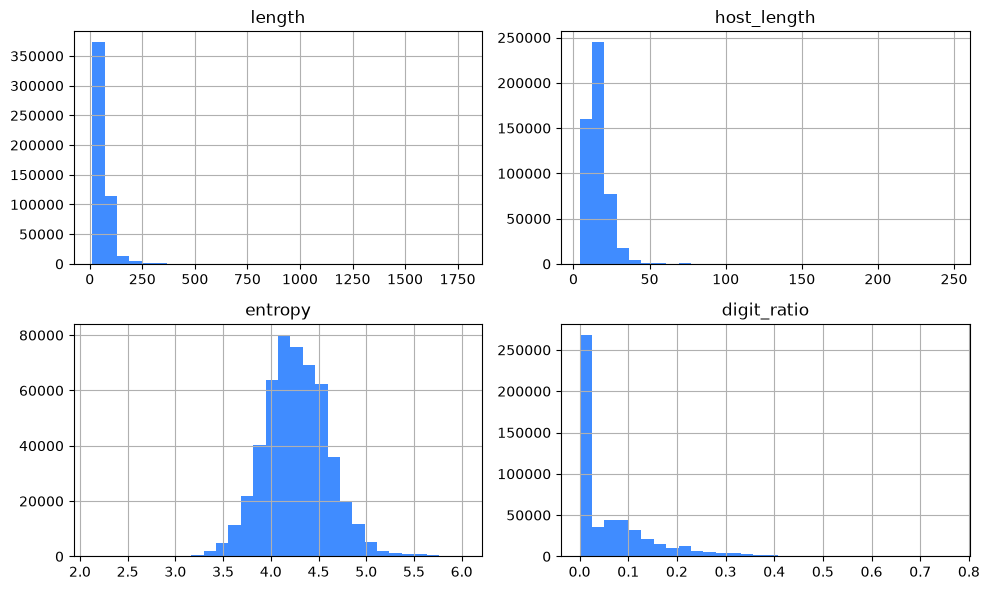

In [4]:
X[['length','host_length','entropy','digit_ratio']].hist(bins=30,figsize=(10,6),color='#408cff'); plt.tight_layout(); plt.savefig(charts/'distributions.png',dpi=180); plt.show()

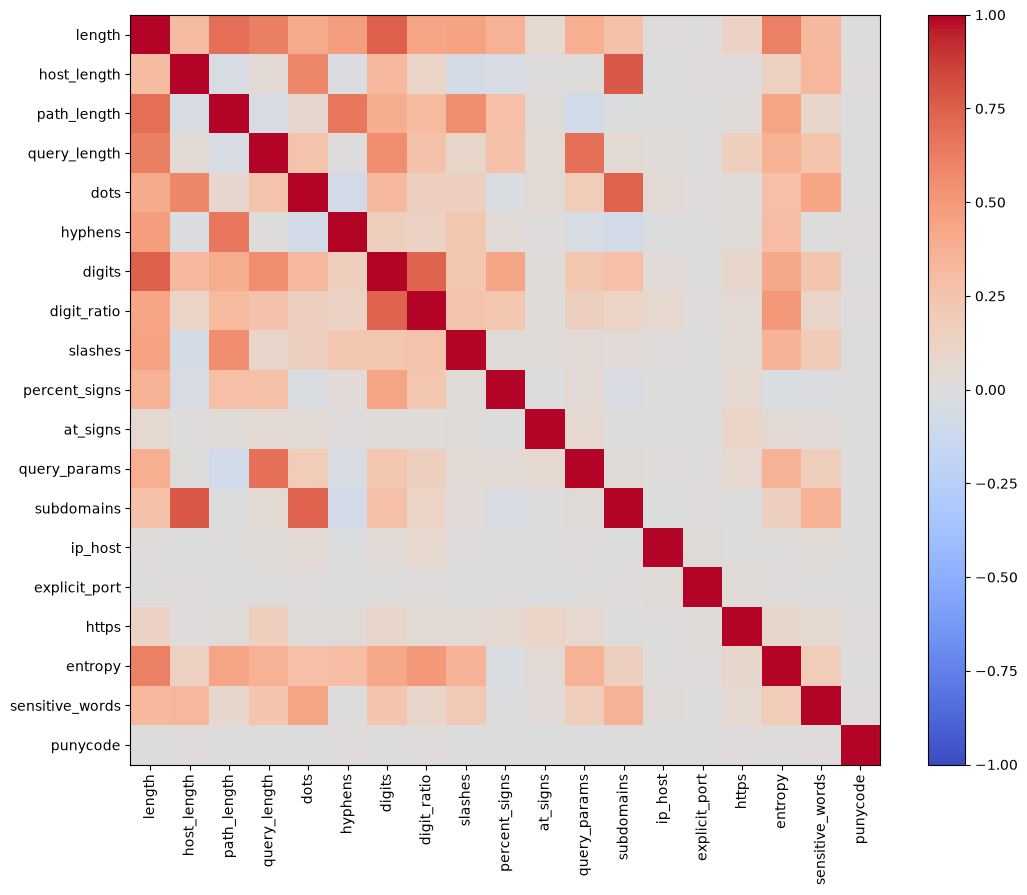

In [5]:
fig,ax=plt.subplots(figsize=(11,9)); im=ax.imshow(X.corr().fillna(0),vmin=-1,vmax=1,cmap='coolwarm'); ax.set_xticks(range(len(X.columns)),X.columns,rotation=90); ax.set_yticks(range(len(X.columns)),X.columns); fig.colorbar(im); plt.tight_layout(); plt.savefig(charts/'correlation.png',dpi=180); plt.show()

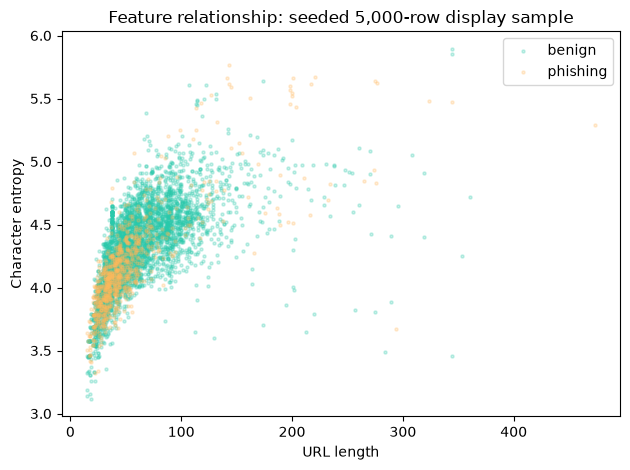

In [6]:
sample=X.assign(label=d.type).sample(min(5000,len(X)),random_state=42)
for label,color in [('benign','#28c9ab'),('phishing','#ffb85c')]:
 p=sample[sample.label==label]; plt.scatter(p.length,p.entropy,s=5,alpha=.25,label=label,color=color)
plt.xlabel('URL length'); plt.ylabel('Character entropy'); plt.legend(); plt.title('Feature relationship: seeded 5,000-row display sample'); plt.tight_layout(); plt.savefig(charts/'relationships.png',dpi=180); plt.show()

## Actual held-out evaluation
The same domain-separated holdout is used for both models. No hyperparameters were tuned against it. The full training entry point is `backend/train.py`; saved pipelines include imputation and scaling where appropriate.

In [7]:
display(pd.DataFrame({name:{k:v for k,v in r.items() if k in ['accuracy','precision','recall','f1','roc_auc','fpr','fnr']} for name,r in m['models'].items()}).T)
for name,r in m['models'].items():
 p=np.load(ROOT/'backend/models'/f'{name}-heldout.npz'); assert np.isclose(accuracy_score(p['truth'],p['prediction']),r['accuracy']); assert np.isclose(roc_auc_score(p['truth'],p['probability']),r['roc_auc'])
print('Saved predictions reproduce measured accuracy and ROC-AUC.')

,accuracy,precision,recall,f1,roc_auc,fpr,fnr
logistic_regression,0.668703,0.324014,0.817130,0.464028,0.805621,0.362892,0.182870
random_forest,0.865824,0.578221,0.870432,0.694855,0.940082,0.135157,0.129568


Saved predictions reproduce measured accuracy and ROC-AUC.


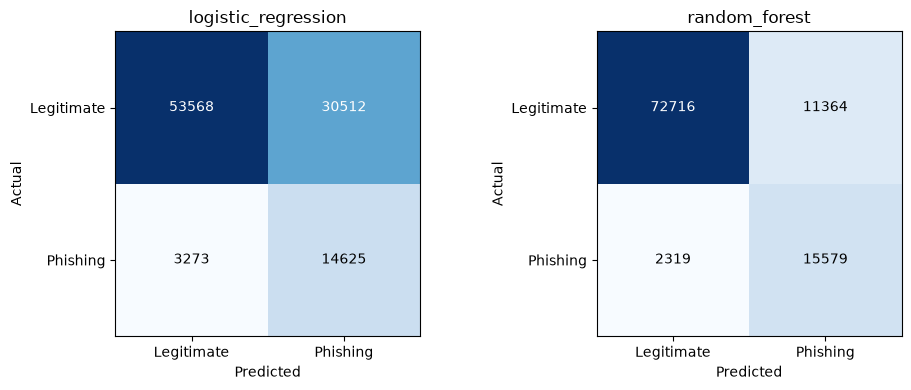

In [8]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(name,r) in zip(axes,m['models'].items()):
 cm=np.array(r['confusion_matrix']); ax.imshow(cm,cmap='Blues'); ax.set_title(name); ax.set_xticks([0,1],['Legitimate','Phishing']); ax.set_yticks([0,1],['Legitimate','Phishing']); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
 for i in range(2):
  for j in range(2): ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
plt.tight_layout(); plt.savefig(charts/'confusion.png',dpi=180); plt.show()

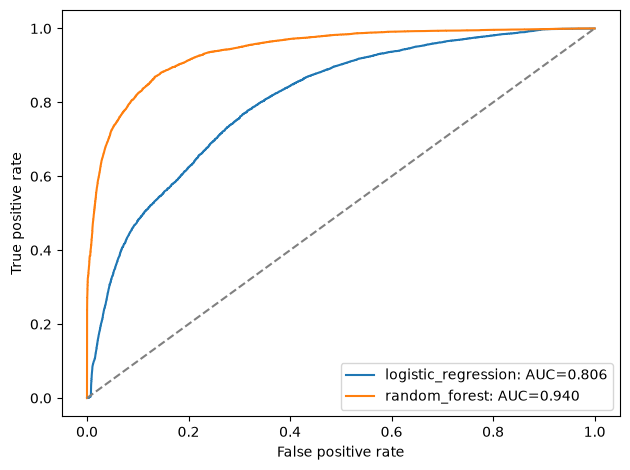

In [9]:
from sklearn.metrics import roc_curve
for name,r in m['models'].items():
 p=np.load(ROOT/'backend/models'/f'{name}-heldout.npz'); fpr,tpr,_=roc_curve(p['truth'],p['probability']); plt.plot(fpr,tpr,label=f'{name}: AUC={r["roc_auc"]:.3f}')
plt.plot([0,1],[0,1],'--',color='gray'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); plt.tight_layout(); plt.savefig(charts/'roc.png',dpi=180); plt.show()

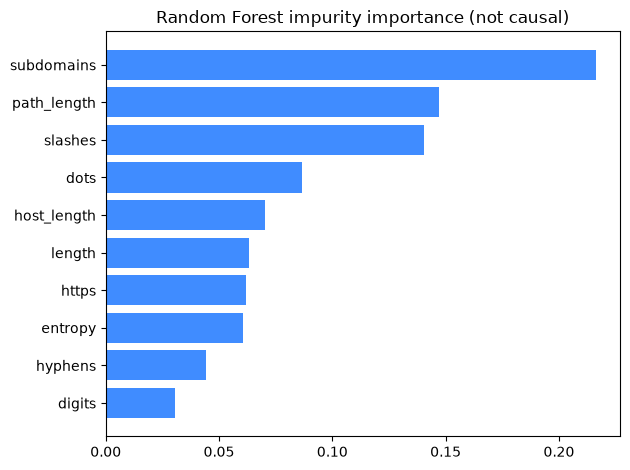

In [10]:
imp=pd.DataFrame(m['models']['random_forest']['importance']).head(10).sort_values('value'); plt.barh(imp.feature,imp.value,color='#408cff'); plt.title('Random Forest impurity importance (not causal)'); plt.tight_layout(); plt.savefig(charts/'importance.png',dpi=180); plt.show()

## Interpretation
Random Forest improves the trade-off on this holdout, but false alarms remain substantial. Long URLs, high entropy and keywords are not proof of phishing; legitimate tracking and compromised trusted hosts are difficult cases. Historical source bias and uncalibrated outputs prevent production safety claims. See the report for false-positive/negative counts and references.